## Daftar Isi

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Import Libraries](#0)<br>
2.  [Fetching Data](#1)<br>
3.  [Waffle Charts](#2) <br>
4.  [Word Clouds](#3) <br>
5.  [Plotting with Seaborn](#4) <br>
6.  [Regression Plots](#5) <br>

</div>


# Import Libraries<a id="0"></a>


In [1]:
# Import and setup matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches # dibutuhkan untuk grafik Waffle

mpl.style.use("ggplot") # untuk gaya grafik seperti ggplot

In [2]:
# Import Primary Modules
import numpy as np # berguna untuk banyak komputasi ilmiah di Python
import pandas as pd # pustaka struktur data utama
from PIL import Image # mengubah gambar menjadi array

In [3]:
# Import seaborn
import seaborn as sns
# Import worldcloud
import wordcloud

In [4]:
# periksa versi terbaru dari beberapa modul berikut
print("Matplotlib version:", mpl.__version__)
print("Seaborn version   :", sns.__version__)
print("WordClour version :", wordcloud.__version__)

Matplotlib version: 3.11.2
Seaborn version   : 0.13.2
WordClour version : 1.9.6


# Fetching Data<a id="1"></a>

Perangkat bantu: Kursus ini sangat bergantung pada [*pandas*](http://pandas.pydata.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) dan [*Numpy*](http://www.numpy.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01) untuk data wrangling, analysis, and visualization. Pustaka plotting utama yang akan kita pelajari dalam kursus ini adalah [Matplotlib](http://matplotlib.org/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkDV0101ENSkillsNetwork20297740-2021-01-01).

Dataset: Immigration to Canada from 1980 to 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) dari website United Nation's

Dataset ini berisi data tahunan tentang arus migran internasional sebagaimana dicatat oleh negara tujuan. Data tersebut menyajikan arus masuk dan arus keluar berdasarkan tempat kelahiran, kewarganegaraan, atau tempat tinggal sebelumnya/berikutnya, baik untuk warga negara asing maupun warga negara Canada. <br><br>Dalam lab ini, kita akan fokus pada data Imigrasi Canada dan menggunakan *dataset yang sudah dibersihkan*.<br><br>
Anda dapat merujuk ke lab tentang pra-pemrosesan data di mana dataset ini dibersihkan untuk menyegarkan kembali keterampilan Pandas Anda dengan cepat. [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/v4/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)



Baca dataset yang sudah tersedia dalam folder data ke dalam dataframe *pandas*.

In [5]:
df_canada = pd.read_csv("../../data/raw/Canada.csv")

Mari kita lihat lima item pertama dalam dataset kita.

In [6]:
df_canada.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Mari kita cari tahu berapa banyak entri yang ada dalam dataset kita.

In [7]:
print(df_canada.shape)

(195, 39)


In [8]:
# Gunakan column Country sebagai indeks
# untuk memudahkan dalam pencarian nama negara

df_canada.set_index("Country", inplace=True)
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


# Waffle Charts <a id="3"></a>

Bagan waffle (`waffle chart`) adalah visualisasi menarik yang biasanya dibuat untuk menampilkan kemajuan menuju tujuan. Ini umumnya merupakan pilihan yang efektif ketika Anda mencoba menambahkan fitur visualisasi yang menarik ke visual yang sebagian besar terdiri dari sel, seperti dasbor Excel.


Mari kita tinjau kembali studi kasus sebelumnya tentang Denmark, Norway, dan Sweden.

In [9]:
# buat dataframe baru untuk ketiga negara diatas
df_dsn = df_canada.loc[["Denmark", "Sweden", "Norway"], :]

# cek hasil dataframenya
df_dsn

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Denmark,Europe,Northern Europe,Developed regions,272,293,299,106,93,73,93,...,62,101,97,108,81,92,93,94,81,3901
Sweden,Europe,Northern Europe,Developed regions,281,308,222,176,128,158,187,...,205,139,193,165,167,159,134,140,140,5866
Norway,Europe,Northern Europe,Developed regions,116,77,106,51,31,54,56,...,57,53,73,66,75,46,49,53,59,2327


Tampaknya ada paket Python baru untuk menghasilkan `waffle chart` yang disebut [PyWaffle](https://github.com/ligyxy/PyWaffle), <br><br>Mari kita buat waffle chart yang sama dengan **pywaffle** sekarang

In [10]:
# import Waffle dari pywaffle
from pywaffle import Waffle

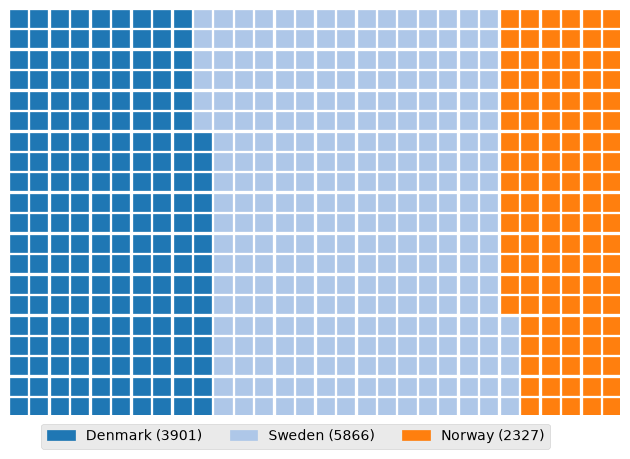

In [11]:
# Siapkan gambar grafik Waffle
fig = plt.figure(
    FigureClass=Waffle,
    rows=20, columns=30, # masukkan jumlah baris dan kolom untuk waffle
    values=df_dsn["Total"], # meneruskan data yang akan digunakan untuk ditampilkan
    cmap_name="tab20", # skema warna
    legend= {
        "labels":[f"{k} ({v})" for k, v in zip(df_dsn.index.values,df_dsn.Total)],
        "loc":"lower left", "bbox_to_anchor":(0.04, -0.1), "ncol":3 
    } 
    # perhatikan penggunaan list comprehension untuk membuat label
    # dari indeks dan total dataset
)

# Tampilkan grafik waffle
plt.savefig("../outputs/waffle_proportions_immigrant_denmark_sweden_norway.png", dpi=200, bbox_inches="tight")
plt.show()

**Pertanyaan:** Buatlah grafik Waffle untuk menampilkan proporsi kontribusi China dan India terhadap total imigrasi.

In [12]:
# buat dataframe baru untuk dua negara diatas
df_CI = df_canada.loc[["China", "India"], :]
df_CI.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
China,Asia,Eastern Asia,Developing regions,5123,6682,3308,1863,1527,1816,1960,...,42584,33518,27642,30037,29622,30391,28502,33024,34129,659962
India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,7150,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904


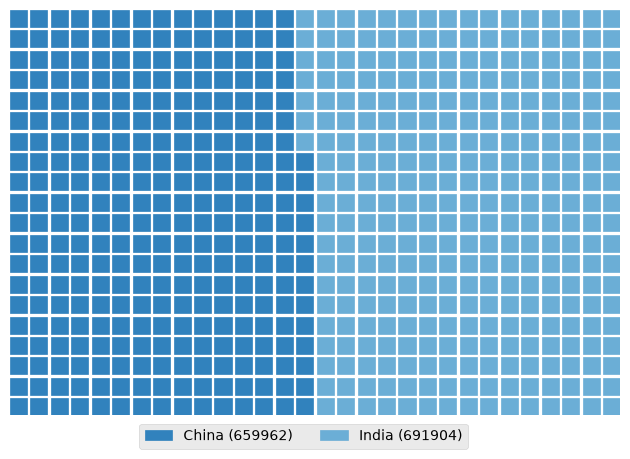

In [13]:
# buat grafik waffle dari dataframe tersebut
fig = plt.figure(
    FigureClass = Waffle,
    rows = 20, columns = 30, # memasukkan jumlah baris dan kolom untuk waffle
    values = df_CI["Total"], # meneruskan data yang digunakan untuk ditampilan
    cmap_name = "tab20c", # skema warna
    legend = {
        "labels" : [f"{k} ({v})" for k, v in zip(df_CI.index.values, df_CI.Total)],
        "loc" : "lower left", "bbox_to_anchor" : (0.2, -0.1), "ncol" : 3
    }
)

# tampilkan grafiknya
plt.savefig("../outputs/waffle_proportions_immigrant_china_india.png", dpi=200, bbox_inches="tight")
plt.show()